In [57]:
import logging
import pandas as pd
from gc_files import GCStore, LocalStore
from audio_files import AudioExtenstion, AudioFile
from recording import Catalog
from signal_treatment import (
    extract_spectral_distribution,
    plot_spectral, band_levels,
    standard_bands, plot_bands_spectrum,
    plot_bands_timeserie,
    acoustic_events,
    extract_spectrum_multiple_files
)
from deployment_metadata import DeploymentMetadata, download_with_metadata
from ais_data import AIS

%load_ext autoreload
%autoreload 2

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [31]:
logging.basicConfig(
    level=logging.WARNING,  
    format="%(asctime)s %(levelname)s %(name)s: %(message)s",
    force=True,
)
logging.getLogger("audio_files").setLevel(logging.INFO)

In [32]:
BUCKET = "noaa-passive-bioacoustic"
FILES_PREFIX = "sefsc/audio/gomex/ef/sefsc_gomex_ef_01"
store = GCStore(bucket=BUCKET)
local_store = LocalStore("downloads")
START_DATE = pd.Timestamp(2016, 7, 31)
END_DATE = pd.Timestamp(2016, 8, 5)

In [33]:
files = store.list_files(prefix=FILES_PREFIX)

In [35]:
files = GCStore.filter_files(
    filenames=files,
    extentions=[AudioExtenstion.FLAC],
    start_date=START_DATE,
    end_date=END_DATE)

In [36]:
download_with_metadata(store, files, dest_dir="downloads", workers=4)

['downloads/sefsc/audio/gomex/ef/sefsc_gomex_ef_01/audio/GOM_EF_01_160731_115002.x.flac',
 'downloads/sefsc/audio/gomex/ef/sefsc_gomex_ef_01/audio/GOM_EF_01_160803_022002.x.flac']

In [37]:
aud = AudioFile(filename=files[0], store=store)

2026-11-22 21:58:05,460 INFO audio_files: GOM_EF_01_160731_115002.x.flac: flac, 2000 Hz, 1 ch, 1 segment(s), 3750.0 min of audio, starts 2016-07-31 11:50:02


In [40]:
meta = DeploymentMetadata.for_audio_file(local_store, files[0])
tf = local_store.download(meta.calibration_files(local_store)[0])

2026-11-22 22:00:48,645 INFO audio_files:  GOM_EF_01_160731_115002.x.flac  fs=2000  1 segment(s)  721 minutes


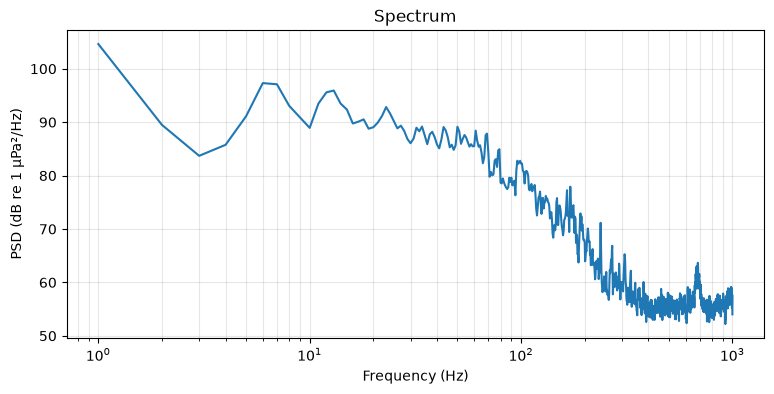

In [42]:
t0 = aud.timestamp
t1 = aud.timestamp  + pd.Timedelta(hours=12)

spectral_densities = extract_spectral_distribution(audio_file=aud, t0=t0, t1=t1, tf_filepath=tf)

times = spectral_densities[0]
freqs = spectral_densities[1]
psds = spectral_densities[2]
instant = 80
plot_spectral(freqs=freqs, psd=psds[instant], calibrated=True)

In [45]:
bands_def = standard_bands(fmax=freqs[-1])

bands_lvl = band_levels(
    freqs=freqs,
    psd_db=psds[instant],
    bands=bands_def)

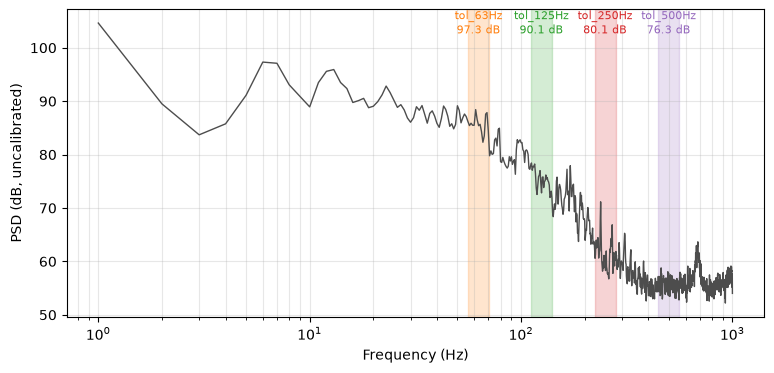

In [46]:
plot_bands_spectrum(freqs=freqs, psd=psds[instant], bands_levels=bands_lvl, bands_def=bands_def)

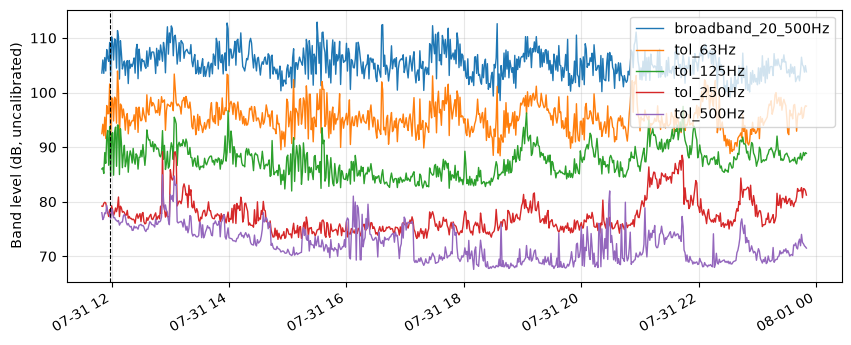

In [47]:
plot_bands_timeserie(times=times, freqs=freqs, psds=psds, bands_def=bands_def, instant=8)

In [48]:
bnd = "broadband_20_500Hz"
events, val, excess=  acoustic_events(times=times, band_level=bands_lvl[bnd], baseline_hours=1)

In [49]:
auds= [AudioFile(filename=f, store=store) for f in files]

2026-11-22 22:04:15,480 INFO audio_files: GOM_EF_01_160731_115002.x.flac: flac, 2000 Hz, 1 ch, 1 segment(s), 3750.0 min of audio, starts 2016-07-31 11:50:02
2026-11-22 22:04:16,329 INFO audio_files: GOM_EF_01_160803_022002.x.flac: flac, 2000 Hz, 1 ch, 1 segment(s), 3750.0 min of audio, starts 2016-08-03 02:20:02


In [ ]:
t0 = auds[0].time_range().start
t1 = auds[len(auds)-1].time_range().end

2026-11-22 22:04:46,257 INFO audio_files: Extracting spectra from 2 file(s) between 2016-07-31 11:50:02 and 2016-08-05 16:50:02 (10 s/min, fmax=1000 Hz, 2 worker(s))
2026-11-22 22:06:25,893 INFO audio_files:  GOM_EF_01_160803_022002.x.flac  fs=2000  1 segment(s)  3750 minutes
2026-11-22 22:06:25,894 INFO audio_files: [2/2] GOM_EF_01_160803_022002.x.flac: 3750 minute(s), 2016-08-03 02:20:02 -> 2016-08-05 16:49:02 (99.6 s)
2026-11-22 22:06:27,606 INFO audio_files:  GOM_EF_01_160731_115002.x.flac  fs=2000  1 segment(s)  3750 minutes
2026-11-22 22:06:27,607 INFO audio_files: [1/2] GOM_EF_01_160731_115002.x.flac: 3750 minute(s), 2016-07-31 11:50:02 -> 2016-08-03 02:19:02 (101.3 s)
2026-11-22 22:06:27,666 INFO audio_files: Done: 7500 spectra x 1000 bins from 2/2 file(s), uncalibrated, 101.4 s total


In [59]:
catalog = Catalog(local_store)
times, freqs, psds, calibrated = extract_spectrum_multiple_files(
    files, t0, t1, catalog=catalog, workers=4,
)

2026-11-22 22:25:17,294 INFO audio_files: Extracting spectra from 2 file(s) between 2016-07-31 11:50:02 and 2016-08-05 16:50:02 (10 s/min, fmax=1000 Hz, 2 worker(s))
2026-11-22 22:25:17,296 INFO audio_files: GOM_EF_01_160803_022002.x.flac: flac, 2000 Hz, 1 ch, 1 segment(s), 3750.0 min of audio, starts 2016-08-03 02:20:02
2026-11-22 22:25:17,297 INFO audio_files: GOM_EF_01_160731_115002.x.flac: flac, 2000 Hz, 1 ch, 1 segment(s), 3750.0 min of audio, starts 2016-07-31 11:50:02
2026-11-22 22:25:26,578 INFO audio_files:  GOM_EF_01_160803_022002.x.flac  fs=2000  1 segment(s)  3750 minutes
2026-11-22 22:25:26,604 INFO audio_files: [2/2] GOM_EF_01_160803_022002.x.flac: 3750 minute(s), 2016-08-03 02:20:02 -> 2016-08-05 16:49:02 (9.3 s)
2026-11-22 22:25:26,739 INFO audio_files:  GOM_EF_01_160731_115002.x.flac  fs=2000  1 segment(s)  3750 minutes
2026-11-22 22:25:26,747 INFO audio_files: [1/2] GOM_EF_01_160731_115002.x.flac: 3750 minute(s), 2016-07-31 11:50:02 -> 2016-08-03 02:19:02 (9.5 s)
2026

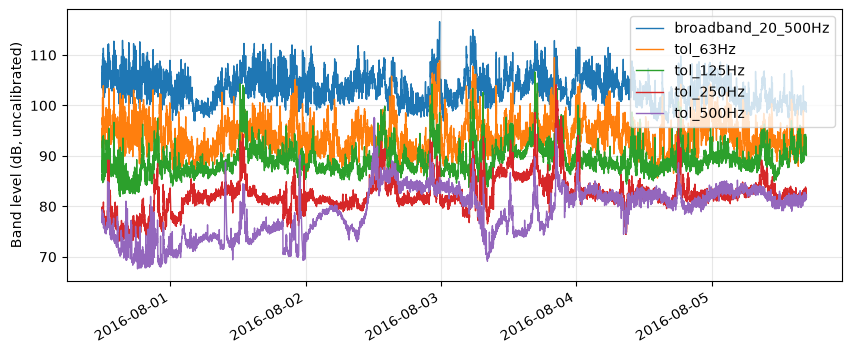

In [60]:
bands_def = standard_bands(fmax=freqs[-1])
plot_bands_timeserie(times=times, freqs=freqs, psds=psds, bands_def=bands_def)

In [61]:
bands_def = standard_bands(fmax=freqs[-1])

bands_lvl = band_levels(
    freqs=freqs,
    psd_db=psds,
    bands=bands_def)

In [62]:
bnd = "tol_500Hz"
events, val, excess=  acoustic_events(times=times, band_level=bands_lvl[bnd], baseline_hours=1)

In [63]:
len(events)

9

In [64]:
events

,start,end,peak_time,peak_level,peak_excess
0,2016-07-31 13:04:02,2016-07-31 13:06:02,2016-07-31 13:04:02,84.715018,8.583234
1,2016-08-01 09:38:02,2016-08-01 09:52:02,2016-08-01 09:46:02,88.748619,14.788073
2,2016-08-01 22:50:02,2016-08-01 23:03:02,2016-08-01 22:57:02,90.189307,15.121174
3,2016-08-03 05:37:02,2016-08-03 05:39:02,2016-08-03 05:39:02,89.452303,7.275427
4,2016-08-03 07:29:02,2016-08-03 07:33:02,2016-08-03 07:31:02,85.769046,10.695141
5,2016-08-03 12:16:02,2016-08-03 12:18:02,2016-08-03 12:18:02,86.672828,8.195448
6,2016-08-03 16:35:02,2016-08-03 16:38:02,2016-08-03 16:35:02,89.834849,8.609356
7,2016-08-03 20:24:02,2016-08-03 20:27:02,2016-08-03 20:26:02,95.461571,10.839114
8,2016-08-03 20:35:02,2016-08-03 20:37:02,2016-08-03 20:36:02,91.953518,7.219599


In [23]:
ais = AIS()
df = ais.load_ais(start=t0, end=t1)

In [24]:
df

,mmsi,base_date_time,latitude,longitude,sog,cog,heading,vessel_name,imo,call_sign,vessel_type,status,length,width,draft,cargo
0,0,2016-07-31 11:59:18,26.09388,-80.17398,0.1,56.0,334.0,EQUULEUS,IMO5146914,ZKWA,0,5,20.0,4.0,3.0,0.0
1,0,2016-07-31 12:26:38,26.09380,-80.17420,0.1,336.0,336.0,EQUULEUS,IMO5146914,ZKWA,0,5,20.0,4.0,3.0,0.0
2,0,2016-07-31 12:29:38,26.09380,-80.17418,0.1,109.0,336.0,EQUULEUS,IMO5146914,ZKWA,0,5,20.0,4.0,3.0,0.0
3,0,2016-07-31 12:32:38,26.09383,-80.17418,0.1,90.0,336.0,EQUULEUS,IMO5146914,ZKWA,0,5,20.0,4.0,3.0,0.0
4,0,2016-07-31 12:35:39,26.09382,-80.17422,0.1,90.0,335.0,EQUULEUS,IMO5146914,ZKWA,0,5,20.0,4.0,3.0,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
43524075,999999999,2016-08-05 16:44:43,25.77342,-80.17967,6.5,257.7,NaN,<NA>,IMO9999999,TEST,52,15,40.0,11.0,0.0,30.0
43524076,999999999,2016-08-05 16:45:53,25.77272,-80.18178,6.4,245.4,NaN,<NA>,IMO9999999,TEST,52,15,40.0,11.0,0.0,30.0
43524077,999999999,2016-08-05 16:47:04,25.77099,-80.18247,6.5,154.9,NaN,<NA>,IMO9999999,TEST,52,15,40.0,11.0,0.0,30.0
43524078,999999999,2016-08-05 16:48:14,25.76892,-80.18214,6.8,190.2,NaN,<NA>,IMO9999999,TEST,52,15,40.0,11.0,0.0,30.0
